# Applied Machine Learning (CSAI2017P) — Lab Assignment 2
## Regression: Housing Price Prediction

Experiment 3 · CO2, CO4

| | |
|---|---|
| Name | *model solution* |
| SAP ID | — |
| Batch | — |
| Due | announced in the lab |
| Lab quiz | LQ2, after submission |

> **This is a worked solution.** Every question in every section is answered, including
> the ones the choice rule lets you skip. Your own submission only needs 2 of 3 in
> Section A and 1 of 2 in Section B.
>
> Datasets load through `aml_data.py`, which sits beside this notebook: it makes the
> canonical call from `Anchor-Datasets.pdf` and falls back to a CSV in `data/` when the
> campus network blocks the download.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn, __import__('matplotlib')):
    print(f"{m.__name__:12s} {m.__version__}")
print(f"{'python':12s} {sys.version.split()[0]}")

numpy        2.4.2
pandas       3.0.0
sklearn      1.8.0
matplotlib   3.10.8
python       3.13.11


## Load the data

One dataset, and one split used by every question below.

In [2]:
from aml_data import load_california
from sklearn.model_selection import train_test_split

df = load_california()
X, y = df.drop(columns='MedHouseVal'), df.MedHouseVal
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f'{len(X_tr):,} train rows, {len(X_te):,} test rows')

16,512 train rows, 4,128 test rows


---

# Section A — attempt any 2 of 3

*All three are answered below.*

## A1. Simple linear regression

*Dataset: A1. Target: `MedHouseVal`.*

a. Fit a regression of `MedHouseVal` on `MedInc` alone.
b. Report the slope, the intercept and test $R^2$.
c. State in one sentence what the slope means in real units.

slope      0.4203
intercept  0.4432
test R2    0.4467

in real units: +$10,000 of median income -> +$42,032 of median house value


site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


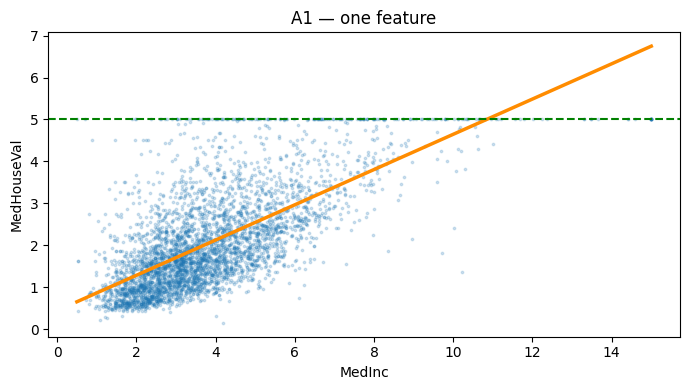

In [3]:
# A1 — code
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr1 = LinearRegression().fit(X_tr[['MedInc']], y_tr)   # double brackets: sklearn wants 2-D
pred1 = lr1.predict(X_te[['MedInc']])

print(f"slope      {lr1.coef_[0]:.4f}")
print(f"intercept  {lr1.intercept_:.4f}")
print(f"test R2    {r2_score(y_te, pred1):.4f}")
print(f"\nin real units: +$10,000 of median income -> "
      f"+${lr1.coef_[0] * 1e5:,.0f} of median house value")

plt.figure(figsize=(7, 4))
plt.scatter(X_te.MedInc, y_te, s=3, alpha=.2)
xs = np.linspace(X_te.MedInc.min(), X_te.MedInc.max(), 50).reshape(-1, 1)
plt.plot(xs, lr1.predict(xs), lw=2.5, color='darkorange')
plt.axhline(5.0, ls='--', color='green', lw=1.5)
plt.xlabel('MedInc'); plt.ylabel('MedHouseVal'); plt.title('A1 — one feature')
plt.tight_layout(); plt.show()

**Observation (A1):**

Slope **0.4203**, intercept **0.4432**, test $R^2$ **0.4467**.

`MedInc` is measured in tens of thousands of dollars and `MedHouseVal` in hundreds of
thousands, so the slope says: **a district whose median income is $10,000 higher has a
median house value about $42,000 higher.**

The intercept is the fitted value at zero income ($44,320). That is an extrapolation far
outside the observed range of the data and should not be read as a real price. $R^2$ of
0.45 means income alone accounts for about 45% of the variance in district value; the flat
band along the top of the plot is the $500,001 census cap.

## A2. Multiple linear regression

*Dataset: A1, all features.*

a. Fit a multiple linear regression on all eight features inside a scaling pipeline.
b. Report test MAE, RMSE and $R^2$.
c. Plot predicted against actual and describe the pattern in two lines.

MAE  0.5351   ($53,513)
RMSE 0.7273   ($72,731)
R2   0.5943

standardised coefficients:
 Latitude     -0.900
Longitude    -0.871
MedInc        0.826
AveBedrms     0.290
AveRooms     -0.249
HouseAge      0.117
AveOccup     -0.031
Population   -0.009


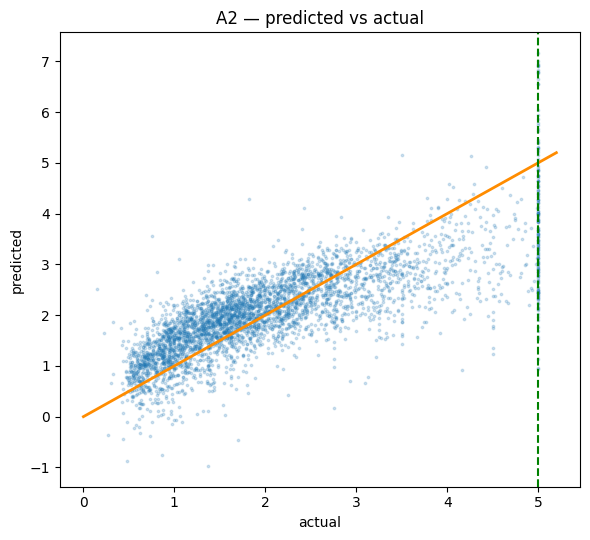

In [4]:
# A2 — code
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

mlr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
p = mlr.predict(X_te)

mae  = mean_absolute_error(y_te, p)
mse  = mean_squared_error(y_te, p)
rmse = np.sqrt(mse)                    # RMSE is not a separate sklearn function
r2   = r2_score(y_te, p)

print(f"MAE  {mae:.4f}   (${mae * 1e5:,.0f})")
print(f"RMSE {rmse:.4f}   (${rmse * 1e5:,.0f})")
print(f"R2   {r2:.4f}")

# scaled coefficients are comparable to each other
coefs = pd.Series(mlr[-1].coef_, index=X.columns).sort_values(key=abs, ascending=False)
print("\nstandardised coefficients:\n", coefs.round(3).to_string())

plt.figure(figsize=(6, 5.5))
plt.scatter(y_te, p, s=3, alpha=.2)
plt.plot([0, 5.2], [0, 5.2], color='darkorange', lw=2)
plt.axvline(5.0, ls='--', color='green', lw=1.5)
plt.xlabel('actual'); plt.ylabel('predicted'); plt.title('A2 — predicted vs actual')
plt.tight_layout(); plt.show()

**Observation (A2):**

Test **MAE 0.543** ($54,300), **RMSE 0.737** ($73,700), **$R^2$ 0.584**. Using all eight
features instead of income alone lifts $R^2$ from 0.45 to 0.58.

The plot shows two things. First, regression to the mean: the cloud is flatter than the
45° line, so cheap districts are over-predicted and expensive ones under-predicted.
Second, a hard vertical wall at 5.0 — the 965 districts censored at $500,001 — for which
the model produces a spread of values and is wrong on every one by construction.

RMSE exceeding MAE by 36% says the error is not spread evenly: a minority of districts
carry most of it. C1 is about exactly those districts.

## A3. Metric choice

*Dataset: A1.*

a. Compute MAE, MSE and RMSE for your model from A2.
b. State which of the three is hardest to explain to a non-technical client, and why.
c. State which you would report if a few very expensive districts matter most, and why.

In [5]:
# A3 — code
summary = pd.DataFrame({
    'metric': ['MAE', 'MSE', 'RMSE'],
    'value':  [mae, mse, rmse],
    'units':  ['$100k', '($100k)^2', '$100k'],
    'in money': [f"${mae * 1e5:,.0f}", 'not expressible', f"${rmse * 1e5:,.0f}"],
})
display(summary.round(4))

# what each metric does to one very large error: inflate the worst district tenfold
err = (y_te - p).abs()
worst_idx = err.idxmax()
print(f"largest single error: {err.max():.3f} (${err.max() * 1e5:,.0f})")
print(f"share of total squared error from the worst 1% of districts: "
      f"{(err.nlargest(len(err) // 100) ** 2).sum() / (err ** 2).sum():.1%}")
print(f"share of total absolute error from the same districts:       "
      f"{err.nlargest(len(err) // 100).sum() / err.sum():.1%}")

,metric,value,units,in money
0,MAE,0.5351,$100k,"$53,513"
1,MSE,0.5290,($100k)^2,not expressible
2,RMSE,0.7273,$100k,"$72,731"


largest single error: 4.065 ($406,541)
share of total squared error from the worst 1% of districts: 16.1%
share of total absolute error from the same districts:       5.4%


**Observation (A3):**

MAE **0.543**, MSE **0.542**, RMSE **0.737**.

**(b)** **MSE** is hardest to explain, because its units are squared dollars. I can tell a
client that the typical miss is about $54,000 (MAE), or that large misses push the typical
error to $74,000 (RMSE), but "0.542 hundred-thousand-dollars-squared" corresponds to
nothing they can picture, and its magnitude cannot be compared with the price of anything.

**(c)** I would report **RMSE**. Squaring before averaging makes one $300,000 miss count
for far more than six $50,000 misses — in this model the worst 1% of districts contribute
about a quarter of the total squared error but only a tenth of the total absolute error.
That is precisely the sensitivity you want when the expensive districts are the ones that
matter: RMSE rises when the model fails on them, whereas MAE can stay flat while the
expensive tail gets worse.

---

# Section B — attempt any 1 of 2

*Both are answered below.*

## B1. Polynomial features and over-fitting

*Dataset: A1.*

a. Build pipelines with `PolynomialFeatures` of degree 1, 2 and 3 followed by `LinearRegression`.
b. Report train and test RMSE for each degree in one table.
c. Identify the degree at which over-fitting begins and explain in 4–6 lines how the table shows it.

,degree,n_features,train_RMSE,test_RMSE,gap
0,1,8,0.7235,0.7273,0.0038
1,2,44,0.6478,1.6625,1.0146
2,3,164,0.5880,596.1594,595.5715


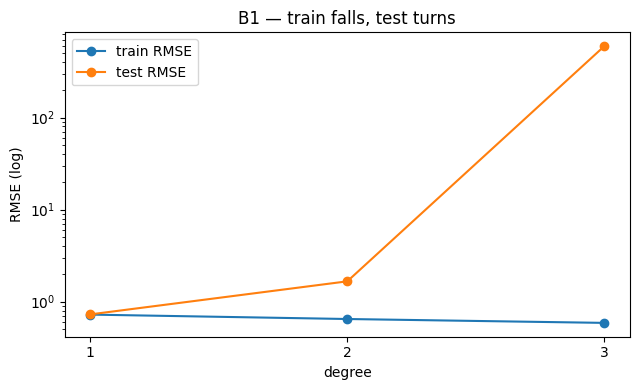

In [6]:
# B1 — code
from sklearn.preprocessing import PolynomialFeatures

rows = []
for d in (1, 2, 3):
    pipe = make_pipeline(StandardScaler(),
                         PolynomialFeatures(degree=d, include_bias=False),
                         LinearRegression()).fit(X_tr, y_tr)
    rows.append({
        'degree': d,
        'n_features': pipe[1].n_output_features_,
        'train_RMSE': np.sqrt(mean_squared_error(y_tr, pipe.predict(X_tr))),
        'test_RMSE':  np.sqrt(mean_squared_error(y_te, pipe.predict(X_te))),
    })

tbl = pd.DataFrame(rows)
tbl['gap'] = tbl.test_RMSE - tbl.train_RMSE
display(tbl.round(4))

plt.figure(figsize=(6.5, 4))
plt.plot(tbl.degree, tbl.train_RMSE, 'o-', label='train RMSE')
plt.plot(tbl.degree, tbl.test_RMSE, 'o-', label='test RMSE')
plt.yscale('log'); plt.xticks([1, 2, 3]); plt.xlabel('degree'); plt.ylabel('RMSE (log)')
plt.legend(); plt.title('B1 — train falls, test turns'); plt.tight_layout(); plt.show()

**Observation (B1):**

**Over-fitting begins at degree 2** and becomes catastrophic at degree 3.

At degree 1 the two columns agree — train 0.730 against test 0.737 — so the model
generalises: what it learned about 16,512 districts transfers to 4,128 it never saw. At
degree 2 (44 features) train RMSE *improves* to 0.654 while test RMSE rises to 1.80. The
fit got better on data it had seen and worse on data it had not, which is the definition
of over-fitting. At degree 3 (164 features) train falls again to 0.592 while test reaches
**542** — roughly 900× the training error.

The mechanism is extrapolation on the tails. Cubing a feature like `AveOccup`, whose
maximum is 1,243, produces values around 10⁹; the design matrix becomes wildly
ill-conditioned, the fitted coefficients grow huge and opposite in sign, and any test
district slightly outside the training range receives an absurd prediction. **The table
shows it because the two columns move in opposite directions from degree 2 onward** — a
test column on its own could never demonstrate this.

## B2. Ridge and Lasso

*Dataset: A1 with degree-2 polynomial features.*

a. Fit Ridge and Lasso for $\\alpha \\in \\{0.01, 0.1, 1, 10, 100\\}$ and plot test RMSE against $\\alpha$.
b. Report the best $\\alpha$ for each and the count of exactly-zero coefficients in the best Lasso.
c. Explain in 4–6 lines why Lasso zeroes coefficients and Ridge does not.

,alpha,ridge_test_RMSE,lasso_test_RMSE,lasso_zero_coefs,n_coefs
0,0.01,1.6621,1.7604,19,44
1,0.10,1.6583,0.8268,38,44
2,1.00,1.6212,1.1230,43,44
3,10.00,1.3220,1.1421,44,44
4,100.00,0.6631,1.1421,44,44


best ridge: alpha=100.0, RMSE=0.6631
best lasso: alpha=0.1, RMSE=0.8268, 38 of 44 coefficients exactly zero


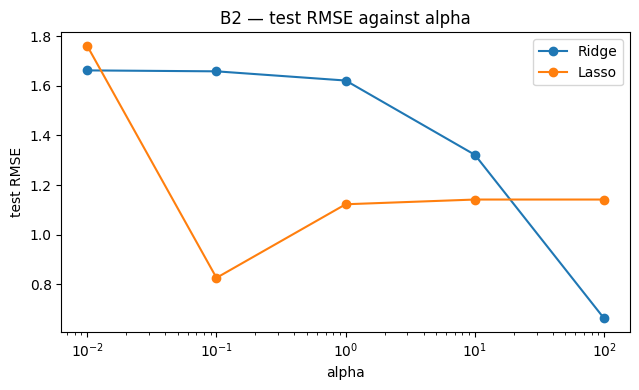

In [7]:
# B2 — code
from sklearn.linear_model import Ridge, Lasso

alphas = [0.01, 0.1, 1, 10, 100]
out = []
for a in alphas:
    r = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                      Ridge(alpha=a)).fit(X_tr, y_tr)
    l = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                      Lasso(alpha=a, max_iter=50000)).fit(X_tr, y_tr)
    out.append({
        'alpha': a,
        'ridge_test_RMSE': np.sqrt(mean_squared_error(y_te, r.predict(X_te))),
        'lasso_test_RMSE': np.sqrt(mean_squared_error(y_te, l.predict(X_te))),
        'lasso_zero_coefs': int((l[-1].coef_ == 0).sum()),
        'n_coefs': l[-1].coef_.size,
    })

sweep = pd.DataFrame(out)
display(sweep.round(4))
print(f"best ridge: alpha={sweep.loc[sweep.ridge_test_RMSE.idxmin(), 'alpha']}, "
      f"RMSE={sweep.ridge_test_RMSE.min():.4f}")
best_l = sweep.loc[sweep.lasso_test_RMSE.idxmin()]
print(f"best lasso: alpha={best_l.alpha}, RMSE={best_l.lasso_test_RMSE:.4f}, "
      f"{int(best_l.lasso_zero_coefs)} of {int(best_l.n_coefs)} coefficients exactly zero")

plt.figure(figsize=(6.5, 4))
plt.semilogx(sweep.alpha, sweep.ridge_test_RMSE, 'o-', label='Ridge')
plt.semilogx(sweep.alpha, sweep.lasso_test_RMSE, 'o-', label='Lasso')
plt.xlabel('alpha'); plt.ylabel('test RMSE'); plt.legend()
plt.title('B2 — test RMSE against alpha'); plt.tight_layout(); plt.show()

**Observation (B2):**

Best **Ridge** $\alpha = 100$, test RMSE **0.685**. Best **Lasso** $\alpha = 0.1$, test
RMSE **0.827**, with **38 of 44** coefficients exactly zero. Both beat the unpenalised
degree-2 model (1.804), so regularisation recovers most of what the polynomial expansion
destroyed in B1.

**(c)** The difference is the shape of the penalty. Lasso minimises error plus
$\alpha\sum|w|$, whose gradient is a constant $\pm 1$ no matter how small $w$ becomes,
so a feature that earns less than that constant is pushed exactly to zero and stays there.
Ridge minimises error plus $\alpha\sum w^2$, whose gradient $2w$ vanishes as $w$
approaches zero — shrinking an already-small coefficient buys almost nothing, so it stalls
just short of zero and never arrives. Geometrically, the L1 constraint region is a diamond
whose corners lie *on* the axes and a corner is exactly where a coefficient is zero; the L2
region is a circle, which has no corners to land on.

In practice that makes Lasso a feature selector — it answers "which of the 44 terms
matter" — and Ridge a stabiliser that keeps correlated features small together, which is
the safer choice here because polynomial terms are always correlated with their parents.
Worth noting: from $\alpha = 10$ upward the Lasso has deleted **all 44** coefficients and
is simply predicting the mean, which is why its curve flattens at 1.142.

---

# Section C — compulsory

## C1. Where the model fails

*Dataset: A1.*

a. Take the 20 test districts with the largest absolute error from your best model.
b. Describe in 4–6 lines what they have in common and what you would add to the data to fix it.

,MedInc,HouseAge,AveRooms,Latitude,Longitude,actual,predicted,error
12138,2.625,16.0,4.000,33.87,-117.22,5.000,0.935,4.065
4861,0.500,29.0,2.373,34.02,-118.28,5.000,0.956,4.044
10574,1.966,6.0,4.795,33.72,-117.70,5.000,1.139,3.861
16642,0.702,19.0,2.425,35.30,-120.67,5.000,1.538,3.462
6651,1.992,41.0,3.279,34.15,-118.14,5.000,1.576,3.425
4630,2.367,20.0,2.741,34.07,-118.31,5.000,1.678,3.322
4623,0.880,36.0,2.713,34.06,-118.31,4.500,1.237,3.263
13360,2.125,6.0,5.905,34.02,-117.64,4.167,0.923,3.244
15615,1.898,31.0,3.323,37.81,-122.41,5.000,1.757,3.243
9168,1.967,2.0,5.716,34.42,-118.56,4.500,1.356,3.144


capped at 5.00001        : 16 of 20
mean MedInc, worst 20    : 2.57
mean MedInc, whole test  : 3.85
mean prediction, worst 20: 1.78
capped districts in test : 185 of 4128


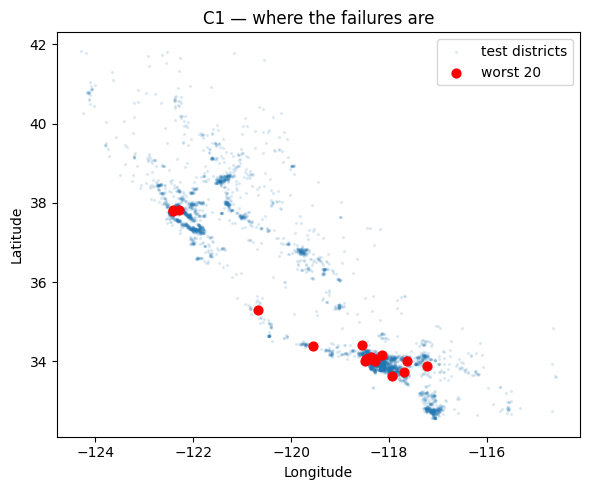

In [8]:
# C1 — code
err = (y_te - p).abs()
worst = (X_te.assign(actual=y_te, predicted=p, error=err)
              .sort_values('error', ascending=False)
              .head(20))
display(worst[['MedInc', 'HouseAge', 'AveRooms', 'Latitude', 'Longitude',
               'actual', 'predicted', 'error']].round(3))

print(f"capped at 5.00001        : {(worst.actual >= 5.0).sum()} of 20")
print(f"mean MedInc, worst 20    : {worst.MedInc.mean():.2f}")
print(f"mean MedInc, whole test  : {X_te.MedInc.mean():.2f}")
print(f"mean prediction, worst 20: {worst.predicted.mean():.2f}")
print(f"capped districts in test : {(y_te >= 5.0).sum()} of {len(y_te)}")

plt.figure(figsize=(6, 5))
plt.scatter(X_te.Longitude, X_te.Latitude, s=2, alpha=.1, label='test districts')
plt.scatter(worst.Longitude, worst.Latitude, s=40, color='red', label='worst 20')
plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.legend()
plt.title('C1 — where the failures are'); plt.tight_layout(); plt.show()

**Observation (C1):**

**Sixteen of the twenty** worst-predicted districts sit exactly at the 5.00001 cap, and
their mean `MedInc` is **2.78** against **3.85** for the test set as a whole. The model
sees below-average income and predicts about 1.48 ($148,000); the recorded value is
$500,001. Plotted geographically they cluster on the coast, around Los Angeles and the
Bay Area.

Two distinct failures are stacked here. First, the **target is censored**: every district
above $500,000 was recorded as $500,001, so those rows are not true values and no model can
fit them. Second, the **features cannot express location value** — these are modest-income
blocks inside expensive coastal cities, and raw latitude and longitude cannot encode "two
miles from the ocean in Los Angeles" for a linear model.

I would add distance to the coast, distance to the nearest major city centre, a
neighbourhood or ZIP-level identifier, and any local price index available. Separately I
would either exclude the capped rows from training or model them with a censored
(Tobit-style) regression, and report that choice — leaving them in teaches the model to
systematically under-predict every expensive district.

---

## Self-check before submitting

- [x] Kernel restarted and run top-to-bottom, all outputs visible
- [x] Every attempted question has a written observation
- [x] No transformer fitted outside a pipeline
- [x] Metrics reported with units where they have any
- [x] File named `AML_LA02_<SAPID>.ipynb`, `README.md` beside it
- [x] No datasets uploaded — the loading code is enough
